# 02 · The group structure: how much it explains, how to evaluate it, how to model it

Notebook 01 predicted the heating load of 192 building designs on three geometries TabPFN had never seen, and found that its error was almost entirely a shift shared by all designs of a geometry. Two limits came with that result. Three held-out geometries are three tests, so any statement about geometries rests on very little. And the models compared there, TabPFN and XGBoost, are handed the shape columns as ordinary inputs; neither is told that the rows come in groups.

This notebook makes the grouping the subject:

1. **How much of the table is the grouping?** The share of the variance that lies between geometries, and what it means for the number of independent examples.
2. **What does a random split hide?** The same models scored on random designs instead of unseen geometries.
3. **Twelve tests instead of three.** Each geometry held out in turn.
4. **Models that know about groups.** A mixed-effects model and a two-stage model as references, and why a mixture model is not the natural tool here.
5. **Bands for a new geometry.** Whether 80% prediction bands cover 80% of the designs when the whole geometry is new, and how to calibrate them with the other geometries' misses.
6. **Which differences between models are real**, with a bootstrap over geometries rather than designs.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd

import helper
from helper import (
    DESIGN_COLUMNS,
    TARGET,
    coverage_by_geometry,
    errors_by_geometry,
    fit_predict_mixed,
    fit_predict_tabpfn,
    fit_predict_two_stage,
    fit_predict_xgboost,
    geometry_names,
    group_calibrated_band,
    grouped_split,
    leave_one_group_out,
    load_energy_efficiency,
    per_geometry_mae,
    plot_group_errors,
    random_split,
    scores,
    variance_shares,
)

helper.configure_plots(plots=True)
helper.init_tabpfn()

frame = load_energy_efficiency()
names = geometry_names(frame)

TabPFN v3.5 weights, running locally


## 2. How much of the table is the grouping?

Two summaries of the heating-load variance answer this. The first is the share explained by each geometry's mean alone: if we knew nothing about a design except its geometry and that geometry's average heating load, how much of the variation would we account for? The second adds one average shift per glazing setup, the same shift for every geometry.

A third summary says what the grouping does to the number of independent examples. The intraclass correlation $\rho$ is the fraction of the variance that two designs of the same geometry share. With $m$ designs per geometry and $n$ designs in all, the variance of an average over the table is inflated by the design effect $1 + (m - 1)\rho$ compared with $n$ independent designs, so the table carries roughly

$$n_{\mathrm{eff}} = \frac{n}{1 + (m - 1)\rho}$$

independent designs' worth of information about anything that varies between geometries.

In [2]:
pd.Series(variance_shares(frame)).round(3)

between                  0.908
with_glazing             0.990
icc                      0.914
designs_per_geometry    64.000
effective_n             13.110
dtype: float64

Nine tenths of the variance lies between geometries (`between`): knowing only a design's geometry and that geometry's average heating load accounts for most of it. One shift per glazing setup brings that to 99% (`with_glazing`). The intraclass correlation is about 0.91, so with 64 designs per geometry the design effect is about 59, and the 768 designs carry roughly 13 independent observations' worth of information about anything that differs between geometries, about as many as there are geometries. For the hard part of the problem, placing a new geometry's level, this is a twelve-point data set.

## 3. What a random split hides

The same models, the same eight columns, and the same number of designs to predict, 192, but drawn at random instead of as three whole geometries. Every geometry then has designs on both sides of the split.

In [3]:
history, current, answers = random_split(frame, n_test=192, seed=0)
random_tabpfn = fit_predict_tabpfn(history, current, DESIGN_COLUMNS)
random_xgb = fit_predict_xgboost(history, current, DESIGN_COLUMNS)

history, current, answers_grouped = grouped_split(frame)
grouped_tabpfn = fit_predict_tabpfn(history, current, DESIGN_COLUMNS)
grouped_xgb = fit_predict_xgboost(history, current, DESIGN_COLUMNS)

pd.DataFrame(
    {
        "random split, TabPFN": scores(answers, random_tabpfn["mean"]),
        "random split, XGBoost": scores(answers, random_xgb["mean"]),
        "three unseen geometries, TabPFN": scores(answers_grouped, grouped_tabpfn["mean"]),
        "three unseen geometries, XGBoost": scores(answers_grouped, grouped_xgb["mean"]),
    }
).T

,mae,r2,signed
"random split, TabPFN",0.360,0.997,0.002
"random split, XGBoost",0.280,0.998,-0.024
"three unseen geometries, TabPFN",0.873,0.979,-0.521
"three unseen geometries, XGBoost",1.904,0.908,-1.725


On random designs both models are nearly perfect, with an MAE around 0.3 and an $R^2$ above 0.99, and XGBoost is slightly better than TabPFN. On unseen geometries the errors are two to seven times larger and the order reverses. A random split asks whether a model can fill in a missing glazing setup for a building whose siblings it has seen. It says almost nothing about a new building form, and here it would even pick the wrong model.

## 4. Twelve tests instead of three

Leave one group out: for each of the twelve geometries, the context is the other eleven, 704 designs, and the 64 designs of the held-out geometry are predicted. Every design in the table is predicted once, by a model that never saw its geometry. Four models:

- **TabPFN**, default constructor, the eight design columns.
- **XGBoost**, default settings, the eight design columns.
- **A mixed-effects model** that knows the rows come in geometries (section 5 explains it).
- **A two-stage model** that predicts a geometry's level from its shape and the effect of glazing inside a geometry separately (section 5).

TabPFN takes about twenty seconds per geometry on a laptop CPU, so this cell runs for a few minutes.

In [4]:
logo = {
    "TabPFN": leave_one_group_out(frame, fit_predict_tabpfn, features=DESIGN_COLUMNS),
    "XGBoost": leave_one_group_out(frame, fit_predict_xgboost, features=DESIGN_COLUMNS),
    "mixed effects": leave_one_group_out(frame, fit_predict_mixed),
    "two-stage": leave_one_group_out(frame, fit_predict_two_stage),
}
overall = pd.DataFrame({name: scores(table["actual"], table["mean"]) for name, table in logo.items()}).T
print(f"TabPFN leave-one-geometry-out MAE: {overall.loc['TabPFN', 'mae']:.6f}")
overall

TabPFN leave-one-geometry-out MAE: 2.780874


,mae,r2,signed
TabPFN,2.781,0.842,-0.564
XGBoost,4.972,0.336,-0.937
mixed effects,2.680,0.870,-0.172
two-stage,2.798,0.816,0.065


In [5]:
by_geometry = errors_by_geometry(
    frame["geometry"], frame[TARGET], {name: table["mean"] for name, table in logo.items()}
)
by_geometry.xs("MAE", axis=1, level=1).rename(index=names.to_dict()).round(2)

,TabPFN,XGBoost,mixed effects,two-stage
geometry,,,,
0.98 / 7.0 m,1.02,3.96,1.97,2.13
0.90 / 7.0 m,4.03,3.10,2.60,1.25
0.86 / 7.0 m,2.23,2.99,2.93,0.76
0.82 / 7.0 m,5.94,13.03,8.42,7.96
0.79 / 7.0 m,10.67,3.16,7.00,11.39
0.76 / 7.0 m,1.64,23.72,1.97,0.66
0.74 / 3.5 m,0.76,0.39,1.00,1.08
0.71 / 3.5 m,0.38,0.45,0.44,0.92
0.69 / 3.5 m,1.26,0.44,0.66,0.81


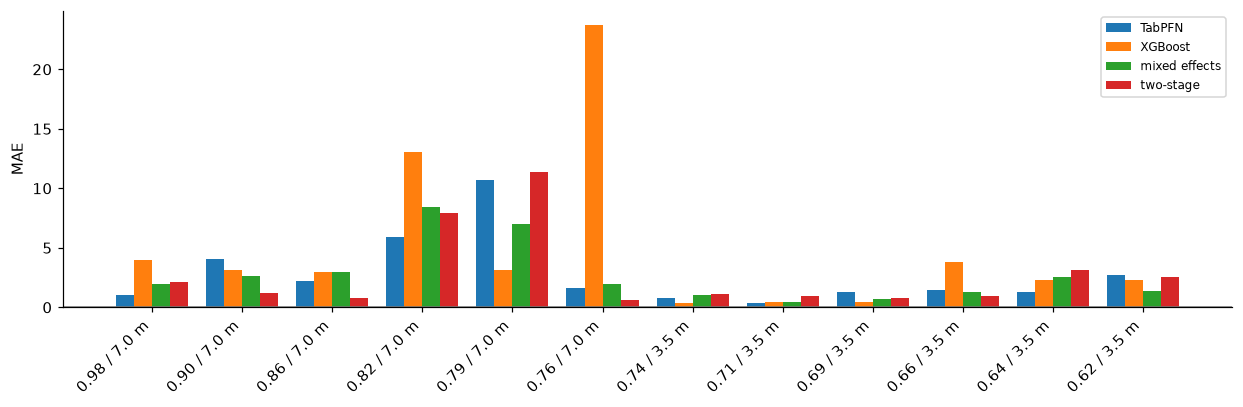

In [6]:
plot_group_errors(by_geometry, names, metric="MAE")

Over twelve geometries the picture is harsher than notebook 01's. TabPFN's MAE is about 2.8 rather than 0.9: the three geometries held out there happen to be among the easier ones. The mixed-effects and two-stage models, small linear and kernel models built around the grouping, are level with it. XGBoost averages about 5, with an $R^2$ near 0.34.

The per-geometry table shows where the error comes from. Two neighbouring two-storey geometries are hard for every model. Compactness 0.79 has a level of about 38.6, the highest in the table, so when it is held out no context geometry is as high; TabPFN and the two-stage model miss it by more than ten units, the mixed model by seven, and XGBoost, unusually, does best at about three. Compactness 0.82, about 25.6, is the lowest two-storey level and sits right next to it in shape; every model misses it by six units or more. Two neighbours that differ by 13 units in heating level mean that whichever one is held out, the models carry over the other's level and miss by several units. In the mixed model's terms (section 5), their offsets are about +1.6 and −2.1 times the typical geometry offset: these are the geometries whose level the shape columns do not explain.

XGBoost's worst geometry, compactness 0.76 at 7.0 m, fails for a different reason. With it held out, compactness separates the context's one-storey geometries, 0.62 to 0.74, from its two-storey ones, 0.79 to 0.98, as cleanly as height does. The held-out 0.76 falls between them, and XGBoost predicts it like a one-storey building, about 12 against a true 36, so its trees evidently relied on compactness. When two columns separate the context's groups equally well, which one a tree uses is arbitrary, and a new group can land on the wrong side. TabPFN, the mixed model and the two-stage model all place this geometry correctly.

## 5. Models that know about groups

**A mixed-effects model.** For design $i$ of geometry $g$, the model writes the heating load as

$$y_{gi} = x_{gi}^{\top}\beta + u_g + \varepsilon_{gi}, \qquad u_g \sim \mathcal{N}(0, \tau^2), \qquad \varepsilon_{gi} \sim \mathcal{N}(0, \sigma^2).$$

Here $x_{gi}$ holds the fixed-effect columns: relative compactness and overall height describe the geometry, the glazing area, glazing distribution and orientation vary inside it, and a glazing-by-height term lets windows matter more on taller buildings. $\beta$ are their coefficients. $u_g$ is the geometry's own offset, the part of its level that the shape columns do not explain, drawn from a distribution with between-geometry variance $\tau^2$; $\varepsilon_{gi}$ is the design-level residual with variance $\sigma^2$.

The model's value for unseen groups is not that it predicts them better. For a geometry outside the context, $u_g$ is unknown, its best guess is 0, and the prediction falls back to the fixed part $x_{gi}^{\top}\beta$. What the model adds is an honest account of the uncertainty: the predictive variance of a design on a new geometry is $\tau^2 + \sigma^2$, not $\sigma^2$. And it separates two kinds of comparison that notebook 01 met informally. The difference between two designs on the same geometry cancels $u_g$, so its variance is $2\sigma^2$. The difference between two designs on two different new geometries carries both offsets, $2\tau^2 + 2\sigma^2$.

Fitted on all twelve geometries:

In [7]:
full = fit_predict_mixed(frame, frame)
tau, sigma = full["tau"], full["sigma"]
print(f"tau (spread of geometry offsets) = {tau:.2f}, sigma (spread within a geometry) = {sigma:.2f}")
print(f"standard deviation of a difference between two designs: same geometry {np.sqrt(2) * sigma:.2f}, "
      f"two different new geometries {np.sqrt(2 * (tau**2 + sigma**2)):.2f}")

tau (spread of geometry offsets) = 3.21, sigma (spread within a geometry) = 0.65
standard deviation of a difference between two designs: same geometry 0.91, two different new geometries 4.63


Geometry offsets vary about five times as much as designs within a geometry. Two designs on the same geometry can be compared to within about one unit; two designs on two different new geometries carry an uncertainty of nearly five units on their difference, before any error in the fixed part. That is the formal version of notebook 01's rule of thumb: compare within a geometry with confidence, across geometries with caution.

**A two-stage model.** The variance shares in section 2 suggest a direct decomposition: predict each geometry's level, then the shift a design's glazing setup produces inside its geometry. Stage 1 fits a Gaussian process to the context geometries' mean heating loads, one point per geometry, as a smooth function of their five shape columns; it learns from as many points as there are geometries, which makes the effective sample size from section 2 concrete. Stage 2 averages, for each combination of overall height, glazing area and glazing distribution, how far designs with that combination sit from their own geometry's mean, so a window setup can matter more on taller buildings.

**Why not a mixture model.** A mixture model infers a hidden group label: it assumes each row came from one of several latent components and estimates which. Here the group is observed, every design's geometry is in its shape columns, so there is nothing hidden to infer. Mixtures earn their place when regimes are unrecorded, for example buildings of an unknown construction type that behave differently. The one regime-like pattern in this table, glazing mattering about twice as much on two-storey buildings, is captured by letting the glazing effect depend on height, as both models above do.

## 6. Bands for a new geometry

Each model gives an 80% prediction band, from its 10% to its 90% quantile. If the bands are calibrated, about 80% of the designs should fall inside. The table shows coverage and mean width per held-out geometry.

In [8]:
tabpfn_logo = logo["TabPFN"]
calibrated_low, calibrated_high = group_calibrated_band(tabpfn_logo, level=0.8)
bands = {
    "TabPFN": (tabpfn_logo["low"], tabpfn_logo["high"]),
    "TabPFN, group-calibrated": (calibrated_low, calibrated_high),
    "mixed effects": (logo["mixed effects"]["low"], logo["mixed effects"]["high"]),
    "two-stage": (logo["two-stage"]["low"], logo["two-stage"]["high"]),
}
coverage = pd.concat(
    {name: coverage_by_geometry(frame["geometry"], frame[TARGET], low, high) for name, (low, high) in bands.items()},
    axis=1,
)
coverage.rename(index={**names.to_dict()}).round(2)

TabPFN        TabPFN, group-calibrated        mixed effects       two-stage       
             coverage  width                 coverage  width      coverage width  coverage  width
geometry                                                                                         
0.98 / 7.0 m     1.00  23.92                     1.00  23.80          1.00  8.78      1.00   9.69
0.90 / 7.0 m     0.97  10.90                     0.91  10.72          1.00  8.62      1.00   9.17
0.86 / 7.0 m     1.00  13.44                     1.00  13.32          0.97  8.54      1.00   9.71
0.82 / 7.0 m     0.44  11.13                     0.28  10.13          0.00  5.61      0.00   4.44
0.79 / 7.0 m     0.00  11.20                     0.00   9.54          0.00  6.98      0.00   5.52
0.76 / 7.0 m     1.00  20.46                     1.00  20.34          1.00  8.76      1.00  15.33
0.74 / 3.5 m     1.00   7.50                     1.00   7.38          1.00  8.85      1.00  10.98
0.71 / 3.5 m     0.98   4.47                     0.98   4.34          1.00  8.87      1.00   9.76
0.69 / 3.5 m     1.00   7.36                     1.00   7.25          1.00  8.87      1.00   9.34
0.66 / 3.5 m     1.00   7.23                     1.00   7.11          1.00  8.82      1.00   9.30
0.64 / 3.5 m     1.00   7.46                     1.00   7.34          1.00  8.65      1.00   9.29
0.62 / 3.5 m     0.48   5.24                     0.00   3.58          1.00  8.82      1.00  10.89
all              0.82  10.86                     0.76  10.40          0.83  8.35      0.83   9.45

Read only the last row and every model looks calibrated: overall coverage between about 0.76 and 0.83 against a nominal 0.80. Read the rows and none of them is. Each band covers nearly every design on most geometries and few or none on the geometries the model gets wrong: none of the 0.79 geometry under any model, and at most half of the 0.82 geometry. A band that is right 80% of the time on average can be wrong for a whole group at once, and for a design team a group is a whole building form. For grouped data, calibration has to be judged per group, and the question becomes what share of groups is covered, not what share of rows.

The group calibration barely moves TabPFN's band, and where it moves it, it narrows it. Its adjustment is the 80% quantile of the other geometries' misses, and since most geometries are covered with room to spare, that quantile lies slightly below zero; the one or two geometries that are badly missed cannot pull it up. Calibrating against groups needs more groups than twelve, or a different target, such as covering a stated share of geometries.

## 7. Which differences between models are real

The unit of replication is the geometry, not the design: the 64 designs of one geometry share its offset, so treating them as 64 independent tests would make every difference look certain. The bootstrap below resamples the twelve geometries with replacement, recomputes each model's mean per-geometry MAE, and gives simultaneous 95% intervals for the differences from TabPFN (max-t, so that the intervals hold together for the whole family). A negative difference favours TabPFN. With twelve units the intervals are coarse, and they are reported as they come.

In [9]:
from tabicllab.bootstrap import maxt_family, resample_indices

per_geometry = pd.DataFrame({name: per_geometry_mae(table) for name, table in logo.items()})
contrasts = {f"TabPFN - {name}": (per_geometry["TabPFN"] - per_geometry[name]).to_numpy()
             for name in per_geometry.columns if name != "TabPFN"}
family = maxt_family(contrasts, resample_indices(len(per_geometry), 10_000, seed=0))
pd.DataFrame(
    {name: {"difference": c["diff"], "low": c["ci_simultaneous"][0], "high": c["ci_simultaneous"][1]}
     for name, c in family["contrasts"].items()}
).T.round(3)

,difference,low,high
TabPFN - XGBoost,-2.191,-9.624,5.242
TabPFN - mixed effects,0.101,-1.539,1.740
TabPFN - two-stage,-0.017,-1.465,1.431


None of the intervals excludes zero. TabPFN's advantage over XGBoost averages more than two units per geometry, but it rests mostly on two geometries where XGBoost fails badly, and resampling twelve geometries cannot rule out that it reflects which geometries happen to exist. Against the mixed-effects and two-stage models TabPFN is level. Twelve groups are too few to separate models whose errors are dominated by a few hard groups, and the per-geometry table is the more informative view.

## What this suggests next

- **The hard geometries are the ones whose level the shape does not predict, and nothing here flags them in advance.** TabPFN's band is no wider for them than for geometries it predicts well, and on the 0.82 geometry every model misses in the same direction by six units or more. More modelling of the same twelve groups cannot fix that; information about the new group can.
- **A few simulations of the new geometry.** The natural next experiment adds $k$ designs of the held-out geometry to the context, for $k$ = 1, 2, 4 and 8, and measures how fast the offset disappears. For TabPFN that is just a longer context; for the mixed model it is the standard estimate of a group's offset from its first observations. Which designs to simulate first, and which geometry to simulate next, is then an experimental-design question.
- **The same evaluation for perturbations.** The lab's main application holds out whole perturbations. Per-group errors, a bootstrap over groups and per-group coverage carry over directly.

The [results page](docs/results/02-grouped-structure.md) repeats every arm with three seeds, adds TabPFN-2 and a compact two-column description of the shape, and is generated by `02_grouped_structure_report.py`.